# MCAI500 M3 In Class Activity

Module 3 focuses on classification methods and reliable evaluation.

# In-class activity

Work in pairs. Complete the missing parts, run the experiments, and write short interpretations in Markdown cells. The goal is not only to obtain a score; it is to explain why the score and predictions change.

## Activity plan

1. Load and inspect the data.
2. Complete the model pipelines.
3. Compare at least three algorithms.
4. Change hyperparameters and record what changes.
5. Interpret a confusion matrix and ROC curve.
6. Decide which model is most appropriate for detecting malignant cases.

In [33]:
# Core tools used throughout the notebook.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    ConfusionMatrixDisplay, make_scorer
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 12)
sns.set_theme(style="whitegrid")


## Task 1: Load the data and define the positive class

**Hint:** Use `load_breast_cancer(as_frame=True)`. The original target is 0 for malignant and 1 for benign. Recode it so malignant is 1. Then create `X` and `y`.

Complete the code below and check the class counts.

In [34]:
dataset = load_breast_cancer(as_frame=True)  # Load the breast cancer dataset as pandas objects.
df = dataset.frame.copy()  # Copy the table containing the features and the original target.
df["target"] = (df["target"] == 0).astype(int)  # Recode the target: malignant becomes 1 and benign becomes 0.
df["target_label"] = df["target"].map({0: "benign", 1: "malignant"})  # Add readable labels for the recoded classes.

X = df.drop(columns=["target", "target_label"])  # Keep only the input features, excluding both target columns to prevent data leakage.
y = df["target"]  # Select the numeric target that the models will learn to predict.

print("Dataset shape:", df.shape)  # Print the number of rows and columns, including the target and label columns.
display(df.head())  # Display the first five rows to inspect the data.
display(y.value_counts().rename(index={0: "benign", 1: "malignant"}).to_frame("count"))  # Count each class, replace numeric labels with names, and display the counts as a table.


Dataset shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,...,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,...,0.7119,0.2654,0.4601,0.11890,1,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,...,0.2416,0.1860,0.2750,0.08902,1,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,...,0.4504,0.2430,0.3613,0.08758,1,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,...,0.6869,0.2575,0.6638,0.17300,1,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,...,0.4000,0.1625,0.2364,0.07678,1,malignant


,count
target,
benign,357
malignant,212


## Task 2: Create a stratified train/test split

Use 20% for testing and `random_state=42`. **Hint:** pass `stratify=y` so that both sets keep similar class proportions.

> We use 20% of the data to test the model on examples it has not seen during training. `random_state=42` makes the split reproducible, and `stratify=y` keeps similar proportions of benign and malignant cases in both sets.

The format is **(number of rows, number of columns)**:

- **Training set shape: `(455, 30)`** → 455 cases to train the model, each with 30 features.
- **Test set shape: `(114, 30)`** → 114 cases to test the model, with the same 30 features.

There are **569 cases** in total, split into approximately **80% for training and 20% for testing**. The `target` column is not included in those 30 features because it is the answer the model must predict.

In [35]:
# TODO: Complete the split.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (455, 30)
Test set shape: (114, 30)


## Task 3: Build three classifiers

Complete the pipelines. Use scaling for Logistic Regression and KNN. Random Forest does not require scaling.

Suggested starting values:
- Logistic Regression: `max_iter=2000`
- KNN: `n_neighbors=7`
- Random Forest: `n_estimators=250`, `max_depth=6`

**Question:** Why might scaling matter for KNN?

Scaling matters for KNN because it uses distances to find the nearest cases. Without scaling, features with larger numerical values can dominate the distance calculation. Scaling puts the features on a comparable scale.

Each pipeline runs these steps in order:

- `SimpleImputer(strategy="median")`: replaces missing values with the median of each feature, learned from the training data.
- `StandardScaler()`: puts features on a comparable scale using the training data's mean and standard deviation.
- `model`: applies the classification algorithm.

We build three different models to compare how well they classify tumors.

| Parameter | Meaning |
|---|---|
| `max_iter=2000` | Allows up to 2,000 iterations to fit Logistic Regression. |
| `n_neighbors=7` | KNN uses the 7 nearest training cases to predict the class. |
| `n_estimators=250` | Random Forest combines 250 decision trees. |
| `max_depth=6` | Limits each tree to a maximum depth of 6. |
| `random_state=42` | Makes randomized operations reproducible. |
| `n_jobs=-1` | Uses all available processor cores for Random Forest. |

Random Forest does not require scaling. The `StandardScaler()` step currently included in its pipeline can be removed.


In [36]:
# TODO: Define the three models.
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=7))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(n_estimators=250,
                                         max_depth=6, 
                                           random_state=RANDOM_STATE,
                                           n_jobs=-1))
    ])
}

## Task 4: Compare metrics

For each model, fit on the training data and calculate accuracy, precision, recall, and F1 on the test data.

**Hint:** Use `model.predict(X_test)`, then `accuracy_score`, `precision_score`, `recall_score`, and `f1_score`.

Remember: the positive class is malignant (1).

In [37]:
rows = []
predictions = {}

for name, model in models.items():
    # Treinar o modelo
    model.fit(X_train, y_train)

    # Prever as classes dos dados de teste
    y_pred = model.predict(X_test)

    # Guardar as previsões para análises posteriores
    predictions[name] = y_pred

    # Comparar as previsões com as respostas corretas
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(3))

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.965,0.975,0.929,0.951
KNN,0.956,0.974,0.905,0.938
Random Forest,0.965,1.000,0.905,0.950


### Interpretation of the results

Since malignant is the positive class, **accuracy** measures overall correctness, **precision** measures how many predicted malignant cases were actually malignant, and **recall** measures how many actual malignant cases were detected. **F1** combines precision and recall.

- **Logistic Regression** achieved 96.5% accuracy, 97.5% precision, 92.9% recall, and an F1 score of 0.951. It had the highest recall and F1, providing the best balance among these results.
- **KNN** achieved 95.6% accuracy, 97.4% precision, 90.5% recall, and an F1 score of 0.938. Its performance was slightly lower.
- **Random Forest** achieved 96.5% accuracy and 100% precision: no benign cases were classified as malignant in this test set. However, its 90.5% recall means that it missed some malignant cases. Its F1 score was 0.950.

**For this exercise's goal of detecting malignant cases, Logistic Regression is the strongest choice among these results**, because it had the highest recall and F1. Perfect precision does not mean that every malignant case was detected. This conclusion applies to this train/test split; cross-validation helps assess whether performance is consistent.


## Task 5: Change model hyperparameters

Run at least two experiments:

- Change KNN `n_neighbors` to 1, 5, 15, and  thirty.
- Change Random Forest `max_depth` to 2, 6, and `None`.
- Change the number of trees to 50 and 300.

Record the test F1 and recall. Do not assume that the largest model is automatically best.

In [38]:
# Experiment 1: Test different numbers of KNN neighbors.
experiment_rows = []  # Create an empty list to store the KNN results.
for k in [1, 5, 15, 30]:  # Repeat the experiment for each number of neighbors.
    candidate = Pipeline([  # Create a pipeline that scales the features before classification.
        ("scaler", StandardScaler()),  # Standardize each feature using statistics learned from the training data.
        ("model", KNeighborsClassifier(n_neighbors=k))  # Configure KNN to use k nearest training cases.
    ])  # Finish defining the pipeline.
    candidate.fit(X_train, y_train)  # Learn the scaling and fit KNN using the training data.
    pred = candidate.predict(X_test)  # Predict benign or malignant for each test case.
    experiment_rows.append({  # Add the current experiment's results to the list.
        "k": k,  # Record the number of neighbors tested.
        "F1": f1_score(y_test, pred),  # Calculate F1, which combines precision and recall.
        "Recall": recall_score(y_test, pred)  # Calculate the proportion of malignant cases detected.
    })  # Finish adding this result.
print("KNN results")  # Print a heading for the KNN results.
display(pd.DataFrame(experiment_rows))  # Convert the results into a table and display it.

# Experiment 2: Test different Random Forest depths while keeping 250 trees.
forest_rows = []  # Create an empty list to store the Random Forest results.
for depth in [2, 6, None]:  # Test depths of 2, 6, and no explicit depth limit.
    candidate = RandomForestClassifier(  # Create a Random Forest classifier for this experiment.
        n_estimators=250,  # Use 250 decision trees for every depth tested.
        max_depth=depth,  # Set the maximum tree depth; None removes the explicit depth limit.
        random_state=RANDOM_STATE,  # Fix the random seed so the experiment is reproducible.
        n_jobs=-1  # Use all available processor cores.
    )  # Finish configuring the classifier.
    candidate.fit(X_train, y_train)  # Train the forest using the training features and labels.
    pred = candidate.predict(X_test)  # Predict the class of each test case.
    forest_rows.append({  # Add the current experiment's results to the list.
        "max_depth": str(depth),  # Store the depth as text so None is displayed clearly.
        "F1": f1_score(y_test, pred),  # Calculate F1 from the true and predicted classes.
        "Recall": recall_score(y_test, pred)  # Calculate the proportion of malignant cases detected.
    })  # Finish adding this result.
print("Random Forest results")  # Print a heading for the Random Forest results.
display(pd.DataFrame(forest_rows))  # Convert the results into a table and display it.


KNN results


,k,F1,Recall
0,1,0.902439,0.880952
1,5,0.938272,0.904762
2,15,0.925000,0.880952
3,30,0.923077,0.857143


Random Forest results


,max_depth,F1,Recall
0,2,0.923077,0.857143
1,6,0.950000,0.904762
2,None,0.962963,0.928571


### Interpretation of the results

- **KNN:** `k=5` performed best among the tested values, with F1 = **0.938** and recall = **90.5%**. Increasing the number of neighbors did not improve performance.
- **Random Forest:** `max_depth=None` performed best, with F1 = **0.963** and recall = **92.9%**. Deeper trees improved both metrics in this experiment.

**Random Forest with no explicit depth limit achieved the highest F1 and recall among these tested configurations.** These results apply to this test split; a larger model is not always better, and cross-validation on the training data can help confirm the choice.


## Task 6: Confusion matrix and error costs

Choose the model with the highest recall, or explain why you choose another one. Plot its confusion matrix.

Then answer: is a false negative or a false positive more concerning in this medical example?

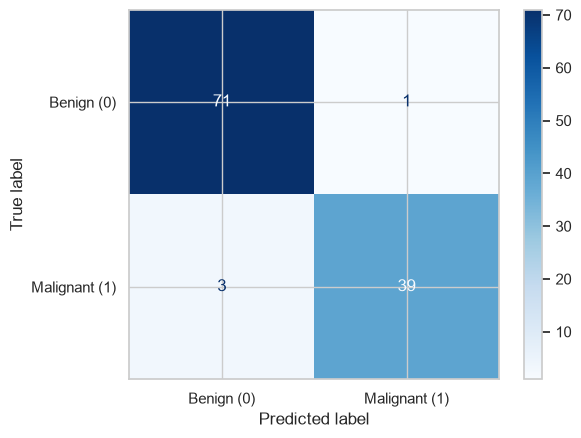

In [39]:
# TODO: Select a model and plot its confusion matrix.
chosen_name = "Logistic Regression"
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[chosen_name],
    display_labels=["Benign (0)", "Malignant (1)"], cmap="Blues"
)
plt.show()

### Confusion Matrix Interpretation

- **71 true negatives:** benign cases correctly classified as benign.
- **1 false positive:** a benign case incorrectly classified as malignant.
- **3 false negatives:** malignant cases incorrectly classified as benign.
- **39 true positives:** malignant cases correctly classified as malignant.

The model correctly classified **110 out of 114 cases (96.5% accuracy)** and detected **39 of the 42 malignant cases (92.9% recall)**.

**False negatives are more concerning in this example**, because classifying a malignant tumor as benign could delay diagnosis and treatment.

## Task 7: Cross-validation

Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` and `cross_validate` or `cross_val_score`. Compare the mean and standard deviation of F1 or ROC-AUC.

**Hint:** Put preprocessing inside the pipeline so each fold learns its scaling only from its training portion.

In [30]:
# TODO: Calculate 5-fold cross-validated F1 for each model.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring="f1")
    print(name, scores["test_score"].mean(), scores["test_score"].std())

Logistic Regression 0.9640480895915677 0.020700447685741707
KNN 0.9574742904154668 0.01161546625918727
Random Forest 0.9457827917269839 0.029640140756685116


### Cross-validation Results

- **Logistic Regression:** mean F1 = **0.964**, standard deviation = **0.021**. It achieved the highest average F1.
- **KNN:** mean F1 = **0.957**, standard deviation = **0.012**. It had the most consistent performance across the five folds.
- **Random Forest:** mean F1 = **0.946**, standard deviation = **0.030**. It had the lowest average F1 and the greatest variation.

Logistic Regression performed best on average, while KNN was the most consistent. Cross-validation evaluates performance across multiple splits rather than relying on a single split.

Cross-validation evaluated the original models: KNN with 7 neighbors and Random Forest with max_depth=6, rather than the configurations selected in Task 5.


## Task 8: ROC curve and threshold experiment

Use `predict_proba` to obtain malignant probabilities. Plot an ROC curve for at least two models. Then compare thresholds 0.30, 0.50, and 0.70 for Logistic Regression.

**Questions:**
- Which threshold gives the highest recall?
- What happens to precision?
- Which threshold would you choose for screening, and why?

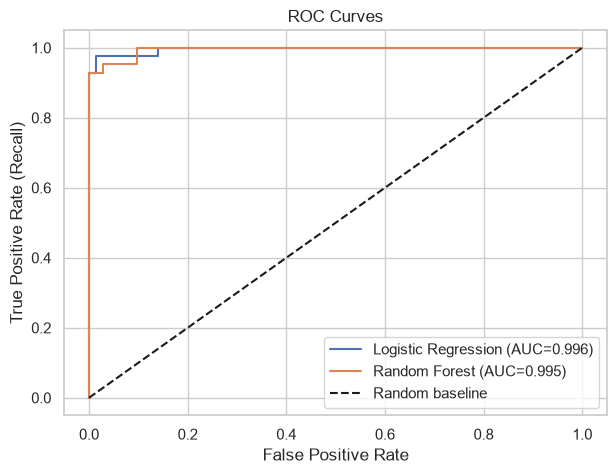

,Threshold,Precision,Recall,F1
0,0.3,0.97619,0.976190,0.97619
1,0.5,0.97500,0.928571,0.95122
2,0.7,1.00000,0.904762,0.95000


In [32]:
# TODO: Fit Logistic Regression and obtain probability scores.
# log_model = models["Logistic Regression"]
# log_model.fit(X_train, y_train)
# probabilities = log_model.predict_proba(X_test)[:, 1]

# TODO: For each threshold in [0.30, 0.50, 0.70], calculate precision, recall, and F1.
# for threshold in [...]:
#     threshold_pred = (probabilities >= threshold).astype(int)
#     print(threshold, precision_score(...), recall_score(...), f1_score(...))

# Plot ROC curves for two models.

plt.figure(figsize=(7, 5))

for name in ["Logistic Regression", "Random Forest"]:
    model = models[name]  # Select the model.
    model.fit(X_train, y_train)  # Train using the training data.
    probabilities = model.predict_proba(X_test)[:, 1]  # Get malignant probabilities.

    fpr, tpr, _ = roc_curve(y_test, probabilities)  # Calculate false positive rate and recall.
    auc = roc_auc_score(y_test, probabilities)  # Calculate the area under the ROC curve.

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend()
plt.show()

# Obtain probabilities from Logistic Regression.
log_model = models["Logistic Regression"]
probabilities = log_model.predict_proba(X_test)[:, 1]

# Compare three classification thresholds.
threshold_rows = []

for threshold in [0.30, 0.50, 0.70]:
    threshold_pred = (probabilities >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1": f1_score(y_test, threshold_pred, zero_division=0)
    })

display(pd.DataFrame(threshold_rows))

### Threshold Experiment Results

- **Threshold 0.30:** achieved the highest recall (97.6%) and F1 (0.976), detecting 41 of 42 malignant cases. Precision was also 97.6%.
- **Threshold 0.50:** recall decreased to 92.9%, while precision was 97.5%. The model missed 3 malignant cases.
- **Threshold 0.70:** precision reached 100%, but recall dropped to 90.5%. The model missed 4 malignant cases.

For this screening exercise, I would choose **0.30** because it detected the most malignant cases while maintaining high precision. Increasing the threshold reduced recall; precision increased overall, although it decreased slightly between 0.30 and 0.50.

## Final student response

Write a short conclusion:

1. Which model performed best according to your chosen metric?
2. Which errors did it make?
3. How did the hyperparameters affect the result?
4. Why can different algorithms produce different predictions on the same data?

### Final Conclusion

1. **Best model:** I prioritized recall because the goal is to detect malignant cases. Logistic Regression with threshold 0.30 achieved the best recall in these test-set experiments. However, because the test set was used to compare thresholds, this choice should be confirmed using validation data before a final independent evaluation. At threshold 0.30, test recall was 97.6% and F1 was 0.976. Logistic Regression also had the highest average F1 in cross-validation (0.964), using its default classification threshold.

2. **Errors:** At threshold 0.30, Logistic Regression missed 1 malignant case (false negative) and classified 1 benign case as malignant (false positive).

3. **Hyperparameters:** KNN performed best with 5 neighbors. Random Forest improved when its depth limit was removed. Lowering the Logistic Regression threshold from 0.50 to 0.30 increased recall from 92.9% to 97.6%.

4. **Different predictions:** The algorithms learn differently. Logistic Regression uses a linear decision boundary, KNN uses nearby training cases, and Random Forest combines decision trees. These approaches can produce different predictions on the same data.

These findings apply to this dataset and the experiments performed. The threshold should be selected using validation data and then evaluated on an untouched test set.


## Train and save the selected model

This cell saves the fitted Logistic Regression pipeline, its feature names, and the experimental threshold of 0.30. It uses the same 80% training split; the test cases are not used for fitting. The threshold was explored on the test set and still requires independent validation.

Run this notebook from the project folder. Then run `python predict_example.py` from that folder to load the saved model and classify a held-out example without retraining.


In [ ]:
# Train and save the selected model (run from the project folder).
from pathlib import Path
import joblib
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Recreate the same data and split so this cell can also run independently.
saved_data = load_breast_cancer(as_frame=True)
saved_X = saved_data.data
saved_y = (saved_data.target == 0).astype(int)  # Malignant = 1; benign = 0.
saved_X_train, _, saved_y_train, _ = train_test_split(
    saved_X, saved_y, test_size=0.20, stratify=saved_y, random_state=42
)

# Keep preprocessing inside the model so it is saved and reused for predictions.
selected_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])
selected_model.fit(saved_X_train, saved_y_train)  # Train on the training set only.

# Save the threshold separately: predict() would otherwise use the default 0.50.
model_bundle = {
    "pipeline": selected_model,
    "threshold": 0.30,
    "feature_names": saved_X.columns.tolist(),
    "labels": {0: "benign", 1: "malignant"},
    "sklearn_version": sklearn.__version__
}
model_path = Path("models") / "logistic_regression.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model_bundle, model_path)
print(f"Model saved to: {model_path.resolve()}")
print(f"Training cases: {len(saved_X_train)}; threshold: {model_bundle['threshold']}")
